# Manufacturing Defect Analysis — Submission Notebook

**Read before you start:**
- Do not rename, delete, reorder, or merge the section headers below (the `## SECTION` lines). The grading system locates your work by these headers.
- For sections with code (Sections 1-3), write and run your code first, then answer the questions in the markdown cell that follows it, using your actual output. For sections without code (Sections 4 onward), just answer in the markdown cell provided. Use the cells as provided — add more cells *within* a section if you need to, but keep the section headers intact and in order.
- Make sure every cell has been run and its output is visible before you submit, and do not delete or edit code cells after running them.
- Chart images will not be read by the grading system — anything the grader needs to know about a chart must also be stated in words in the markdown cell for that section.
- Wherever this template asks you to **state** something (e.g. your chart type, your test name), write it as a plain sentence. Do not rely on the grader inferring it from your code or your chart.


## SECTION 1: DATA PREPARATION

Clean the dataset in the code cell below. Then, in the answer cell that follows, describe the cleaning steps you applied and why. A short list is fine.

**Step 1.1 – Load the data**

First we import the four libraries used in this notebook: pandas (tables), numpy (maths), matplotlib (charts) and scipy.stats (statistical tests). We also store the name of the variable we are studying in one place (`chosen_var`) so every later step uses the same name. Then we read the CSV file into a table called `raw_df` (the untouched, raw data) and check its size and column types.

In [1]:
# Import the libraries used in this notebook
import pandas as pd                 # pandas: tables (DataFrames)
import numpy as np                  # numpy: numbers, arrays and maths
import matplotlib.pyplot as plt     # matplotlib: charts
from scipy import stats             # scipy.stats: statistical tests

# The process parameter we compare between the Defect and No Defect groups.
# It is written ONCE here and used everywhere else in the notebook.
chosen_var = 'Clamping_Pressure'

# Read the CSV file (it must be in the same folder as this notebook)
raw_df = pd.read_csv('G19_data.csv')

# Size of the table: (number of rows, number of columns)
print('Shape of raw_df (rows, columns):', raw_df.shape)

# Data type of every column (we expect numbers only)
print()
print('Data type of each column:')
print(raw_df.dtypes)

# Confirm that every column is numeric
numeric_columns = raw_df.select_dtypes(include='number').columns
print()
print('Numeric columns:', len(numeric_columns), 'out of', len(raw_df.columns))

# Show the first 5 rows. This is the LAST line of the cell,
# so Jupyter draws it as a neat table.
raw_df.head()

Shape of raw_df (rows, columns): (1000, 21)

Data type of each column:
Cutting_Speed            float64
Feed_Rate                float64
Spindle_Speed            float64
Tool_Wear                float64
Coolant_Temperature      float64
Vibration_Amplitude      float64
Workpiece_Hardness       float64
Ambient_Temperature      float64
Humidity                 float64
Tool_Angle               float64
Clamping_Pressure        float64
Machine_Load             float64
Material_Thickness       float64
Surface_Roughness        float64
Power_Consumption        float64
Conveyor_Speed           float64
Alignment_Error          float64
Tool_Change_Frequency    float64
Lubricant_Flow_Rate      float64
Cycle_Time               float64
defect                     int64
dtype: object

Numeric columns: 21 out of 21


,Cutting_Speed,Feed_Rate,Spindle_Speed,Tool_Wear,Coolant_Temperature,Vibration_Amplitude,Workpiece_Hardness,Ambient_Temperature,Humidity,Tool_Angle,Clamping_Pressure,Machine_Load,Material_Thickness,Surface_Roughness,Power_Consumption,Conveyor_Speed,Alignment_Error,Tool_Change_Frequency,Lubricant_Flow_Rate,Cycle_Time,defect
0,92.6,0.3,7217.9,0.5,47.2,4.1,43.2,36.4,53.8,30.0,80.8,48.6,7.5,2.9,17.7,5.2,0.6,5.6,45.7,190.8,1
1,178.9,0.3,6656.6,0.5,46.0,10.0,43.5,29.4,54.7,26.6,97.4,65.4,4.8,1.8,12.7,5.6,0.7,5.3,47.0,146.3,0
2,173.1,0.2,5466.0,0.6,34.1,9.1,42.3,31.9,65.4,22.2,103.2,52.2,4.8,2.8,11.3,3.4,1.2,3.8,63.1,158.8,1
3,146.6,0.4,4136.0,0.6,43.4,6.3,55.3,22.3,61.5,35.0,85.2,46.3,7.9,2.8,15.0,7.1,0.8,4.3,57.3,238.5,0
4,253.5,0.3,6782.8,0.8,36.7,10.4,57.8,24.9,73.8,42.5,98.5,36.2,5.0,1.6,11.4,5.6,1.0,3.8,75.7,105.3,1


**Step 1.2 – Check the target column**

The column `defect` tells us whether each unit was defective (1) or not (0). Before using it to make two groups, we count how many rows fall into each value and confirm that no other values (such as 2, -1 or a blank) are hiding in the column.

In [2]:
# Count the rows for each value in the defect column
defect_counts = raw_df['defect'].value_counts()
print('Number of rows for each value of defect:')
print(defect_counts)

# List the distinct values that appear in the column
distinct_defect_values = sorted(raw_df['defect'].unique().tolist())
print()
print('Distinct values found in defect:', distinct_defect_values)

# isin([0, 1]) is True for a row if the value is 0 or 1; all() checks every row
only_zero_and_one = raw_df['defect'].isin([0, 1]).all()
print('Does defect contain only 0 and 1?', only_zero_and_one)

Number of rows for each value of defect:
defect
0    663
1    337
Name: count, dtype: int64

Distinct values found in defect: [0, 1]
Does defect contain only 0 and 1? True


**Step 1.3 – Look for missing values**

Missing values (blanks, shown as NaN) can break calculations, so we count them in two ways. First we count the blanks in each column. Then we count how many blanks each row has, which tells us whether the missing values are scattered randomly or come in patterns.

In [3]:
# isna() gives True where a value is missing; sum() adds up the Trues in each column
missing_per_column = raw_df.isna().sum()
print('Missing values in each column:')
print(missing_per_column)

# sum(axis=1) adds up across each ROW instead: how many blanks does each row have?
missing_per_row = raw_df.isna().sum(axis=1)

# value_counts() then tells us how many rows have 0 blanks, 1 blank, 20 blanks, etc.
# sort_index() puts the answers in order of the number of blanks.
print()
print('Number of rows (right) that have this many blanks (left):')
print(missing_per_row.value_counts().sort_index())

# Look more closely at the rows with exactly 1 blank: which column is blank?
rows_with_one_blank = raw_df[missing_per_row == 1]
print()
print('Rows with exactly 1 blank:', len(rows_with_one_blank))
print('Of these, rows where the blank is Machine_Load:',
      rows_with_one_blank['Machine_Load'].isna().sum())

Missing values in each column:
Cutting_Speed            10
Feed_Rate                10
Spindle_Speed            10
Tool_Wear                10
Coolant_Temperature      10
Vibration_Amplitude      10
Workpiece_Hardness       10
Ambient_Temperature      10
Humidity                 10
Tool_Angle               10
Clamping_Pressure        10
Machine_Load             59
Material_Thickness       10
Surface_Roughness        10
Power_Consumption        10
Conveyor_Speed           10
Alignment_Error          10
Tool_Change_Frequency    10
Lubricant_Flow_Rate      10
Cycle_Time               10
defect                    0
dtype: int64

Number of rows (right) that have this many blanks (left):
0     941
1      49
20     10
Name: count, dtype: int64

Rows with exactly 1 blank: 49
Of these, rows where the blank is Machine_Load: 49


**Step 1.4 – Look for duplicated rows**

Duplicated rows would count the same unit twice. `duplicated()` marks a row as a duplicate if an identical row appeared earlier in the table. We then check whether these duplicates are the same rows that are completely blank, because two blank rows with the same `defect` value look identical to the computer.

In [4]:
# duplicated() is True for a row if an identical row appeared EARLIER in the table
duplicate_rows = raw_df.duplicated()
print('Number of duplicated rows in raw_df:', duplicate_rows.sum())

# The 20 process parameters are all the columns except 'defect'
parameter_columns = raw_df.columns.drop('defect')
print('Number of parameter columns:', len(parameter_columns))

# For each row: is it True that ALL 20 parameter columns are blank?
all_parameters_blank = raw_df[parameter_columns].isna().all(axis=1)
print('Rows where all 20 parameters are blank:', all_parameters_blank.sum())

# '&' means AND: rows that are duplicated AND completely blank
duplicated_and_blank = duplicate_rows & all_parameters_blank
print('Duplicated rows that are completely blank:', duplicated_and_blank.sum(),
      'out of', duplicate_rows.sum())

# Why? A completely blank row only differs from another blank row by its defect
# value (0 or 1). So the 10 blank rows contain only 2 different patterns,
# and the other 8 are flagged as "duplicates" of them.

Number of duplicated rows in raw_df: 8
Number of parameter columns: 20
Rows where all 20 parameters are blank: 10
Duplicated rows that are completely blank: 8 out of 8


**Step 1.5 – Remove the completely blank rows**

A row with all 20 parameters blank contains no measurements at all, so it cannot say anything about the process and we remove it. The cleaned table is called `clean_df`. We then re-check duplicates and missing values to confirm what is left.

In [5]:
# Number of rows before removing anything
rows_before = len(raw_df)

# Keep only the rows that are NOT completely blank.
# The symbol ~ means NOT, so ~all_parameters_blank is True for every row that has data.
# copy() makes an independent table, so later changes cannot affect raw_df.
# We do NOT reset the row numbers (index), so every row can still be traced
# back to its position in the original CSV file.
clean_df = raw_df[~all_parameters_blank].copy()

# Report what was removed
rows_removed = rows_before - len(clean_df)
print('Rows before cleaning:', rows_before)
print('Rows removed (all 20 parameters blank):', rows_removed)
print('Shape of clean_df (rows, columns):', clean_df.shape)

# Re-check duplicates now that the blank rows are gone
print('Duplicated rows in clean_df:', clean_df.duplicated().sum())

# Which columns still contain missing values? (only columns with at least 1 shown)
missing_after_cleaning = clean_df.isna().sum()
print()
print('Missing values still in clean_df:')
print(missing_after_cleaning[missing_after_cleaning > 0])

# DECISION: the rows with a missing Machine_Load are KEPT.
#  - Clamping_Pressure (the variable analysed here) is valid in all of them.
#  - Machine_Load is not used in this analysis, so its blanks do no harm.
#  - We do NOT fill the blanks (no imputation), because inventing values
#    would add numbers that were never measured.

Rows before cleaning: 1000
Rows removed (all 20 parameters blank): 10
Shape of clean_df (rows, columns): (990, 21)
Duplicated rows in clean_df: 0

Missing values still in clean_df:
Machine_Load    49
dtype: int64


**Step 1.6 – Check that the values are plausible**

Now we look at the minimum and maximum of all 20 parameters, and count any negative or zero values. A negative pressure or speed would be impossible, and an unexpected zero may be a recording error. We are looking for anything that does not make physical sense.

In [6]:
# describe() gives count, mean, std, min, quartiles and max for each column.
# .T (transpose) turns it around so that each parameter is one row.
describe_table = clean_df[parameter_columns].describe().T
print('Summary of all 20 parameters (check the min and max columns):')
print(describe_table.round(2).to_string())

# Count negative values in each parameter column
negative_counts = (clean_df[parameter_columns] < 0).sum()
print()
print('Total negative values in all parameters:', negative_counts.sum())

# Count values that are exactly zero in each parameter column
zero_counts = (clean_df[parameter_columns] == 0).sum()
print()
print('Columns that contain zero values (count of zeros):')
print(zero_counts[zero_counts > 0])

# Find the row number (index) of the Feed_Rate = 0.0 row
zero_feed_rate_rows = clean_df.index[clean_df['Feed_Rate'] == 0]
print()
print('Row number(s) where Feed_Rate = 0.0:', zero_feed_rate_rows.tolist())

# DECISION: nothing is removed.
#  - There are no negative values.
#  - Zero Tool_Wear (a new tool) and zero Alignment_Error are possible readings.
#  - Feed_Rate = 0.0 in a single row is unusual for a machine that is cutting,
#    but Feed_Rate is not used in this analysis, so the row is KEPT.

Summary of all 20 parameters (check the min and max columns):
                       count     mean      std     min      25%      50%      75%      max
Cutting_Speed          990.0   180.07    35.49    50.0   159.77   182.95   202.30    300.0
Feed_Rate              990.0     0.27     0.07     0.0     0.20     0.30     0.30      0.5
Spindle_Speed          990.0  5755.57  1380.70  1000.0  4821.00  5792.50  6734.38  10000.0
Tool_Wear              990.0     0.51     0.18     0.0     0.40     0.50     0.60      1.0
Coolant_Temperature    990.0    43.18     5.36    20.0    39.70    43.05    46.90     60.0
Vibration_Amplitude    990.0     8.62     1.90     1.0     7.40     8.60     9.90     15.0
Workpiece_Hardness     990.0    45.06     8.35    20.0    39.30    45.40    50.70     70.0
Ambient_Temperature    990.0    27.42     3.51    15.0    25.00    27.55    29.70     40.0
Humidity               990.0    59.93     8.68    30.0    54.10    59.15    65.20     90.0
Tool_Angle             990.0

**Step 1.7 – Check for a redundant column**

Two columns that always move together carry the same information. We test this for `Humidity` and `Lubricant_Flow_Rate` by calculating their correlation (r) and fitting a straight line through them. A correlation very close to 1 means one column can be predicted almost perfectly from the other.

In [7]:
# Correlation coefficient r between the two columns (+1 = perfect straight line upwards)
humidity_flow_correlation = clean_df['Humidity'].corr(clean_df['Lubricant_Flow_Rate'])

# Straight-line fit: Lubricant_Flow_Rate = slope x Humidity + intercept
# The last number (1) means "fit a straight line" (a polynomial of degree 1).
line_slope, line_intercept = np.polyfit(clean_df['Humidity'], clean_df['Lubricant_Flow_Rate'], 1)

print(f"Correlation between Humidity and Lubricant_Flow_Rate: r = {humidity_flow_correlation:.5f}")
print(f"Straight-line fit: Lubricant_Flow_Rate = {line_slope:.2f} x Humidity + ({line_intercept:.2f})")

# FLAGGED ONLY: r is almost exactly 1, so Lubricant_Flow_Rate is (almost) a
# rescaled copy of Humidity. Neither column is used in this analysis,
# so nothing is removed or changed.

Correlation between Humidity and Lubricant_Flow_Rate: r = 0.99999
Straight-line fit: Lubricant_Flow_Rate = 1.50 x Humidity + (-35.00)


**Step 1.8 – Check for outliers in the chosen variable**

An outlier is a value far away from the rest. We use the 1.5 × IQR rule on all 990 clamping pressure readings: any value below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR is flagged. Flagging a value does not mean it is wrong, so we also look at each flagged value before deciding what to do.

In [8]:
# All valid values of the chosen variable in the cleaned data
pressure_values = clean_df[chosen_var]

# Quartiles: Q1 has 25% of the values below it, Q3 has 75% below it
q1 = pressure_values.quantile(0.25)
q3 = pressure_values.quantile(0.75)

# IQR (interquartile range) = the spread of the middle 50% of the values
iqr = q3 - q1

# Fences of the 1.5 x IQR rule
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

print(f"Number of values checked: {len(pressure_values)}")
print(f"Smallest value: {pressure_values.min():.1f} bar")
print(f"Largest value:  {pressure_values.max():.1f} bar")
print(f"Q1 = {q1:.2f} bar")
print(f"Q3 = {q3:.2f} bar")
print(f"IQR = {iqr:.2f} bar")
print(f"Lower fence = {lower_fence:.2f} bar")
print(f"Upper fence = {upper_fence:.2f} bar")

# True for a value that is below the lower fence OR ('|') above the upper fence
is_outside_fences = (pressure_values < lower_fence) | (pressure_values > upper_fence)
print(f"Number of values outside the fences: {is_outside_fences.sum()}")

# List those rows with their defect label, smallest pressure first
outlier_rows = clean_df.loc[is_outside_fences, [chosen_var, 'defect']].sort_values(chosen_var)
print()
print('Values outside the fences (left = row number in the original data):')
print(outlier_rows)

# DECISION: all of these are KEPT.
#  - Every one of them lies between 50 and 150 bar, which is a plausible
#    clamping pressure range.
#  - There is no evidence of a recording error, so removing them would be
#    deleting genuine measurements.

Number of values checked: 990
Smallest value: 50.0 bar
Largest value:  150.0 bar
Q1 = 89.00 bar
Q3 = 109.65 bar
IQR = 20.65 bar
Lower fence = 58.02 bar
Upper fence = 140.62 bar
Number of values outside the fences: 9

Values outside the fences (left = row number in the original data):
     Clamping_Pressure  defect
927               50.0       0
488               53.4       0
716               53.6       0
348              141.3       0
641              142.3       1
325              146.3       1
143              147.1       1
63               148.8       0
698              150.0       1


**Step 1.9 – Final sample summary and the two groups**

We finish by counting how many units have a valid clamping pressure and how many fall into each group. We then split the clamping pressure values into two lists: `defect_group` (defect = 1) and `no_defect_group` (defect = 0). These two groups are used in Sections 2 and 3.

In [9]:
# Number of units that have a valid (not blank) clamping pressure
valid_pressure_count = clean_df[chosen_var].notna().sum()

# Split the chosen variable into the two groups using the defect column
defect_group = clean_df.loc[clean_df['defect'] == 1, chosen_var]
no_defect_group = clean_df.loc[clean_df['defect'] == 0, chosen_var]

print(f"Units with a valid {chosen_var}: {valid_pressure_count}")
print(f"Defect group (defect = 1):    {len(defect_group)} units")
print(f"No Defect group (defect = 0): {len(no_defect_group)} units")

# Check: the two groups together should add up to all valid units
print('Groups add up to the total?', len(defect_group) + len(no_defect_group) == valid_pressure_count)

# Check: neither group should contain a blank value
print('Blank values in Defect group:', defect_group.isna().sum())
print('Blank values in No Defect group:', no_defect_group.isna().sum())

Units with a valid Clamping_Pressure: 990
Defect group (defect = 1):    336 units
No Defect group (defect = 0): 654 units
Groups add up to the total? True
Blank values in Defect group: 0
Blank values in No Defect group: 0


**Your answer:**

I inspected **all 1,000 rows and all 21 columns** (20 parameters + `defect`), not only my chosen variable. What I found and what I did:

1. **Data types and target column** – All 20 parameters are numeric (`float64`) and `defect` contains only 0 and 1 (663 No Defect and 337 Defect in the raw file). No type conversion was needed.
2. **Completely blank rows – 10 rows removed.** 10 rows had all 20 parameters missing; only the `defect` label was filled in. A unit with no measurements cannot be placed on any chart or included in any test, and there is nothing to estimate the missing values from, so I removed these 10 rows.
3. **Duplicates – 8 flagged, 0 real.** `duplicated()` flagged 8 rows, but my check showed all 8 were blank rows from step 2 (they only look identical because they are empty). After removing the blank rows, the duplicate count was 0, so no real production unit was recorded twice and no further rows were removed.
4. **Missing `Machine_Load` only – 49 rows kept.** 49 other rows were complete except for `Machine_Load`. I kept them and did **not** fill in (impute) the missing values, because their `Clamping_Pressure` and `defect` values are valid and `Machine_Load` is not used in my comparison. Dropping them would have thrown away 49 valid units (about 5% of the data) for no benefit.
5. **Range and plausibility check (all 20 parameters).** No column has negative values, and every minimum and maximum is physically realistic (for example `Clamping_Pressure` 50.0 to 150.0 bar, `Spindle_Speed` 1,000 to 10,000 RPM). Zero values: `Tool_Wear` = 0.0 mm in 8 rows (a new tool, plausible), `Alignment_Error` = 0.0 mm in 2 rows (perfect alignment, plausible) and `Feed_Rate` = 0.0 mm/rev in 1 row (row 942). A zero feed would mean the tool is not advancing, but `Feed_Rate` is only recorded to one decimal place, so this is most likely a small feed rounded down. I **flagged but kept** this row: it does not affect `Clamping_Pressure`, and deleting it would lose a valid pressure reading.
6. **Redundant column flagged.** `Lubricant_Flow_Rate` is an exact straight-line copy of `Humidity` (r = 0.99999; Lubricant_Flow_Rate = 1.50 $\times$ Humidity - 35.0). Lubricant flow should not physically be set by room humidity, so this looks like a derived or wrongly logged column. It does not affect my analysis, so no change was made, but it should be noted for the machine-learning section because the two columns carry the same information.
7. **Outliers in `Clamping_Pressure` – 9 flagged, all kept.** The 1.5 $\times$ IQR rule (Q1 = 89.00, Q3 = 109.65, IQR = 20.65 bar; fences 58.02 and 140.62 bar) flagged 9 of 990 values: 3 low (50.0, 53.4, 53.6 bar) and 6 high (141.3 to 150.0 bar). All lie inside 50 to 150 bar, a realistic clamping range, and nothing suggests a recording error, so I kept them. Four of the six high values are defective units, so deleting them would artificially shrink the very difference I am testing.

**Resulting sample size:** 990 units with a valid `Clamping_Pressure` – **336 Defect and 654 No Defect**. In total 10 rows were removed and no values were changed.

## SECTION 2: VISUAL ANALYSIS

Choose one of the twenty process parameters to compare between Defect and No Defect groups, and produce your chart and descriptive statistics in the code cell below. Then, in the answer cell that follows, state your variable and chart type explicitly, justify your chart choice, and report the pattern you observe.

**Step 2.1 – Box plot (main chart) and histograms (supporting chart)**

The left chart is a box plot of clamping pressure for each group. The box shows the middle 50% of the units, the line inside is the median, and the whiskers show the normal range. Every single unit is also drawn as a faint dot (spread sideways slightly so the dots do not sit on top of each other). The right chart overlays two histograms to show the shape of each group's distribution, using the `defect_group` and `no_defect_group` from Step 1.9.

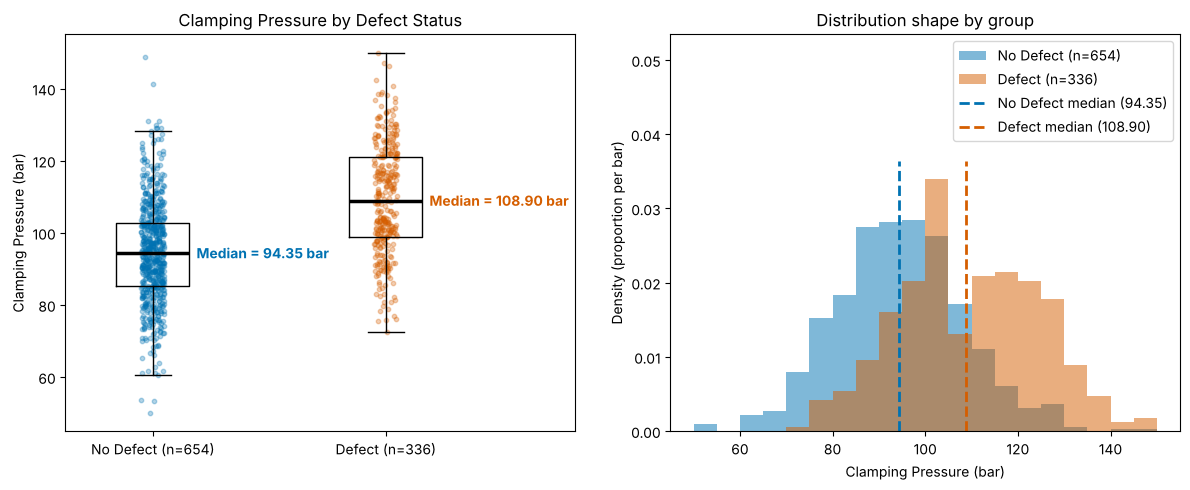

In [10]:
# Colours (colour-blind friendly): blue = No Defect, vermillion = Defect
colour_no_defect = '#0072B2'
colour_defect = '#D55E00'

# Group sizes and medians, used in the labels
n_no_defect = len(no_defect_group)
n_defect = len(defect_group)
median_no_defect = no_defect_group.median()
median_defect = defect_group.median()

# Horizontal position of each box (the boxes are spaced apart to leave room for the median labels)
position_no_defect = 1
position_defect = 2.6

# One figure with two charts side by side
fig, (ax_box, ax_hist) = plt.subplots(1, 2, figsize=(12, 5))

# ---------- LEFT CHART: box plot with every unit drawn as a dot ----------
# whis=1.5 -> whiskers reach the furthest value within 1.5 x IQR of the box
# showfliers=False -> do not draw the points beyond the whiskers a second time,
#                     because every unit is already drawn as a dot below
# medianprops: draw the median line in thick black so it stands out from the coloured dots
ax_box.boxplot([no_defect_group, defect_group],
               positions=[position_no_defect, position_defect],
               widths=0.5,
               whis=1.5,
               showmeans=False,
               showfliers=False,
               medianprops={'color': 'black', 'linewidth': 2.5})

# Jitter: a small random sideways shift so the dots do not sit on one vertical line.
# The seed makes the "random" shifts the same every time the cell is run.
np.random.seed(42)
x_no_defect = position_no_defect + np.random.uniform(-0.08, 0.08, size=n_no_defect)
x_defect = position_defect + np.random.uniform(-0.08, 0.08, size=n_defect)

# Draw every unit as a small, semi-transparent dot (alpha = 0.3)
ax_box.scatter(x_no_defect, no_defect_group, s=10, alpha=0.3, color=colour_no_defect)
ax_box.scatter(x_defect, defect_group, s=10, alpha=0.3, color=colour_defect)

# Write the median value next to each box
ax_box.text(position_no_defect + 0.3, median_no_defect, f"Median = {median_no_defect:.2f} bar",
            va='center', ha='left', color=colour_no_defect, fontweight='bold')
ax_box.text(position_defect + 0.3, median_defect, f"Median = {median_defect:.2f} bar",
            va='center', ha='left', color=colour_defect, fontweight='bold')

# Labels and title
ax_box.set_xticks([position_no_defect, position_defect])
ax_box.set_xticklabels([f"No Defect (n={n_no_defect})", f"Defect (n={n_defect})"])
ax_box.set_xlim(0.4, 3.9)    # extra room on the right for the median labels
ax_box.set_ylabel('Clamping Pressure (bar)')
ax_box.set_title('Clamping Pressure by Defect Status')

# ---------- RIGHT CHART: overlaid histograms ----------
# Same bins for both groups: 50, 55, 60, ... 150
histogram_bins = np.arange(50, 155, 5)

# density=True makes the total area of each histogram equal to 1, so the groups
# can be compared fairly even though they have different numbers of units.
ax_hist.hist(no_defect_group, bins=histogram_bins, density=True, alpha=0.5,
             color=colour_no_defect, label=f"No Defect (n={n_no_defect})")
ax_hist.hist(defect_group, bins=histogram_bins, density=True, alpha=0.5,
             color=colour_defect, label=f"Defect (n={n_defect})")

# Dashed vertical line at the median of each group.
# ymax=0.68 stops each line at 68% of the chart height, so it stays below the legend.
ax_hist.axvline(median_no_defect, ymax=0.68, color=colour_no_defect, linestyle='--', linewidth=2,
                label=f"No Defect median ({median_no_defect:.2f})")
ax_hist.axvline(median_defect, ymax=0.68, color=colour_defect, linestyle='--', linewidth=2,
                label=f"Defect median ({median_defect:.2f})")

ax_hist.set_xlabel('Clamping Pressure (bar)')
ax_hist.set_ylabel('Density (proportion per bar)')
ax_hist.set_title('Distribution shape by group')

# Add 50% empty space above the tallest bar so the legend does not cover the data
ax_hist.set_ylim(0, ax_hist.get_ylim()[1] * 1.5)
ax_hist.legend(loc='upper right')

# Tidy the spacing and draw the figure
plt.tight_layout()
plt.show()

**Step 2.2 – Descriptive statistics for each group**

Charts show the pattern, but numbers let us state it precisely. For each group we calculate the count, mean, standard deviation, median, quartiles, IQR, minimum, maximum, skewness (how lopsided the shape is) and kurtosis (how heavy the tails are). We then compare the two groups by taking the difference in medians and means, and count the points that lie beyond the whiskers of the box plot.

In [11]:
# The two groups, labelled, so we can calculate the same statistics for each
group_dict = {'No Defect': no_defect_group, 'Defect': defect_group}

table_rows = []                  # one entry per group will be added here
points_beyond_whiskers = {}      # number of points beyond the whiskers, per group

for group_name, values in group_dict.items():
    # Quartiles and IQR of this group.
    # float() turns the numpy number into an ordinary Python number, so that round()
    # below gives the usual answer when we round by hand (85.325 -> 85.33).
    group_q1 = float(values.quantile(0.25))
    group_q3 = float(values.quantile(0.75))
    group_iqr = group_q3 - group_q1

    # Whisker limits of the box plot (1.5 x IQR rule applied to THIS group only)
    group_lower_fence = group_q1 - 1.5 * group_iqr
    group_upper_fence = group_q3 + 1.5 * group_iqr
    beyond_whiskers = (values < group_lower_fence) | (values > group_upper_fence)
    points_beyond_whiskers[group_name] = beyond_whiskers.sum()

    # One row of the table. std() is the sample standard deviation (divides by n - 1).
    # The IQR is worked out from the unrounded Q1 and Q3, so it can differ by 0.01
    # from (rounded Q3 - rounded Q1).
    table_rows.append({
        'Group': group_name,
        'n': len(values),
        'mean': round(values.mean(), 2),
        'std': round(values.std(), 2),
        'median': round(values.median(), 2),
        'Q1': round(group_q1, 2),
        'Q3': round(group_q3, 2),
        'IQR': round(group_iqr, 2),
        'min': round(values.min(), 2),
        'max': round(values.max(), 2),
        'skewness': round(stats.skew(values), 3),        # 0 = symmetrical
        'kurtosis': round(stats.kurtosis(values), 3),    # excess kurtosis: 0 = normal-like tails
    })

# Turn the list of rows into a table and print it
group_stats_table = pd.DataFrame(table_rows).set_index('Group')
print(f"Descriptive statistics of {chosen_var} (bar):")
print(group_stats_table.to_string())

# Differences between the groups (Defect minus No Defect)
median_difference = defect_group.median() - no_defect_group.median()
mean_difference = defect_group.mean() - no_defect_group.mean()
print()
print(f"Difference in medians (Defect - No Defect): {median_difference:.2f} bar")
print(f"Difference in means   (Defect - No Defect): {mean_difference:.2f} bar")

# Points drawn beyond the whiskers of each box
print()
print('Points beyond the box plot whiskers (1.5 x IQR rule, each group on its own):')
for group_name, count in points_beyond_whiskers.items():
    print(f"  {group_name}: {count}")

Descriptive statistics of Clamping_Pressure (bar):
             n    mean    std  median     Q1      Q3    IQR   min    max  skewness  kurtosis
Group                                                                                       
No Defect  654   94.54  13.85   94.35  85.33  102.78  17.45  50.0  148.8     0.166      0.42
Defect     336  109.24  15.15  108.90  98.88  121.12  22.25  72.5  150.0     0.052     -0.55

Difference in medians (Defect - No Defect): 14.55 bar
Difference in means   (Defect - No Defect): 14.70 bar

Points beyond the box plot whiskers (1.5 x IQR rule, each group on its own):
  No Defect: 11
  Defect: 0


**Step 2.3 – Defect rate by clamping pressure band**

Another way to see the pattern is to cut the clamping pressure into bands and ask: in each band, what percentage of units were defective? We use `pd.cut` to sort every unit into a band, then count the units and the defective units in each band. If clamping pressure and defects are linked, the defect rate will change from band to band, and a bar chart (with the overall defect rate as a dashed line for comparison) makes this easy to see.

Defect rate by clamping pressure band (bar):
Pressure band  Units  Defective units  Defect rate (%)
          <90    278               33             11.9
      90–<100    246               61             24.8
     100–<110    221               79             35.7
     110–<120    127               71             55.9
         ≥120    118               92             78.0

Total units in all bands: 990
Total defective units in all bands: 336
Overall defect rate: 33.9%


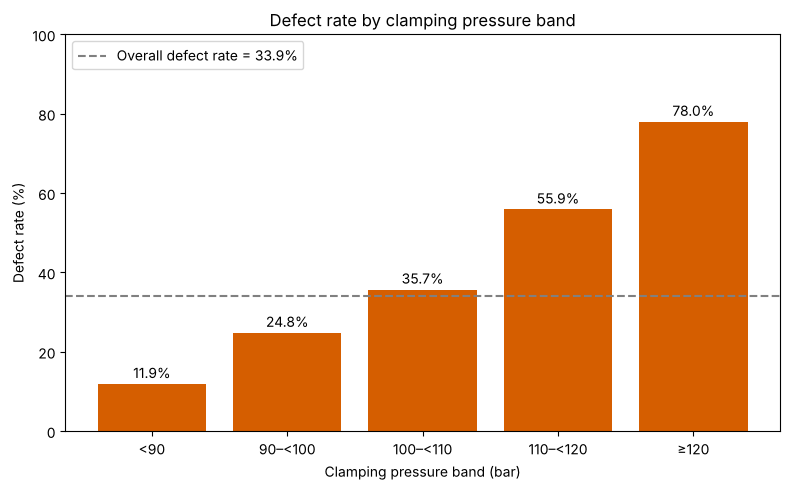

In [12]:
# Band edges and names. right=False means each band includes its LEFT edge but not
# its right edge, e.g. '90–<100' means 90 <= pressure < 100.
band_edges = [0, 90, 100, 110, 120, 200]
band_labels = ['<90', '90–<100', '100–<110', '110–<120', '≥120']

# Work on a small copy so clean_df itself is not changed
band_df = clean_df[[chosen_var, 'defect']].copy()
band_df['pressure_band'] = pd.cut(band_df[chosen_var], bins=band_edges,
                                  labels=band_labels, right=False)

# Count units and defective units in each band, one band at a time
band_rows = []
for band_name in band_labels:
    rows_in_band = band_df[band_df['pressure_band'] == band_name]
    units_in_band = len(rows_in_band)
    defective_in_band = rows_in_band['defect'].sum()       # defect is 1 or 0, so sum = count of 1s
    defect_rate_percent = defective_in_band / units_in_band * 100
    band_rows.append({
        'Pressure band': band_name,
        'Units': units_in_band,
        'Defective units': defective_in_band,
        'Defect rate (%)': round(defect_rate_percent, 1),
    })

band_table = pd.DataFrame(band_rows)
print('Defect rate by clamping pressure band (bar):')
print(band_table.to_string(index=False))

# Check that no unit was lost when sorting into bands
print()
print('Total units in all bands:', band_table['Units'].sum())
print('Total defective units in all bands:', band_table['Defective units'].sum())

# Overall defect rate for comparison (the average of a 0/1 column is the proportion of 1s)
overall_defect_rate = clean_df['defect'].mean() * 100
print(f"Overall defect rate: {overall_defect_rate:.1f}%")

# ---------- Bar chart of the table above ----------
# One bar per clamping pressure band
bar_positions = np.arange(len(band_table))
defect_rates = band_table['Defect rate (%)']

fig, ax_bar = plt.subplots(figsize=(8, 5))
ax_bar.bar(bar_positions, defect_rates, color='#D55E00')

# Write the defect rate above each bar
for position, rate in zip(bar_positions, defect_rates):
    ax_bar.text(position, rate + 1.5, f"{rate:.1f}%", ha='center')

# Dashed line at the overall defect rate
ax_bar.axhline(overall_defect_rate, color='grey', linestyle='--',
               label=f"Overall defect rate = {overall_defect_rate:.1f}%")

# Axis labels, title and band names under the bars
ax_bar.set_xticks(bar_positions)
ax_bar.set_xticklabels(band_table['Pressure band'])
ax_bar.set_xlabel('Clamping pressure band (bar)')
ax_bar.set_ylabel('Defect rate (%)')
ax_bar.set_ylim(0, 100)
ax_bar.set_title('Defect rate by clamping pressure band')
ax_bar.legend(loc='upper left')

plt.tight_layout()
plt.show()

**Step 2.4 – Which other parameters move together with clamping pressure?**

Clamping pressure is only one of 20 parameters, and parameters in a machine often change together. Here we check which of the other 19 parameters are correlated with clamping pressure, using the Pearson correlation r (from -1 to +1; values near 0 mean no straight-line link). This matters because a correlation is not proof of cause: if clamping pressure moves together with another parameter, we cannot be sure which one is really linked to the defects.

In [13]:
# Keep the 20 process parameters only (drop the defect column)
parameters_df = clean_df.drop(columns='defect')

# corr() gives the Pearson correlation between every pair of parameters.
# We take the column for the chosen variable and remove its correlation with itself (always 1).
# For Machine_Load, corr() automatically ignores the rows where Machine_Load is blank.
correlation_with_chosen = parameters_df.corr()[chosen_var].drop(chosen_var)

# Sort from the strongest link to the weakest, ignoring the sign (abs = absolute value)
strongest_first = correlation_with_chosen.abs().sort_values(ascending=False).index
sorted_correlations = correlation_with_chosen[strongest_first]

print(f"Pearson correlation of {chosen_var} with the other 19 parameters (strongest first):")
print(sorted_correlations.round(2))

# The three parameters most strongly correlated with the chosen variable
top_three_parameters = sorted_correlations.index[:3]

# Do these three parameters also differ between the Defect and No Defect groups?
print()
print('Median of the three most correlated parameters, by group:')
for parameter_name in top_three_parameters:
    defect_median = clean_df.loc[clean_df['defect'] == 1, parameter_name].median()
    no_defect_median = clean_df.loc[clean_df['defect'] == 0, parameter_name].median()
    print(f"  {parameter_name}: Defect = {defect_median:.2f}, No Defect = {no_defect_median:.2f}")

# A strong correlation here means clamping pressure does not change on its own.
# We can only say these parameters move TOGETHER; the data alone cannot show which
# one (if any) actually causes the defects.

Pearson correlation of Clamping_Pressure with the other 19 parameters (strongest first):
Tool_Wear               -0.76
Machine_Load             0.63
Material_Thickness      -0.55
Power_Consumption        0.53
Vibration_Amplitude      0.45
Tool_Angle              -0.45
Lubricant_Flow_Rate      0.35
Humidity                 0.35
Alignment_Error         -0.25
Cycle_Time               0.16
Conveyor_Speed          -0.08
Cutting_Speed           -0.08
Feed_Rate               -0.07
Coolant_Temperature      0.04
Ambient_Temperature      0.03
Workpiece_Hardness       0.03
Tool_Change_Frequency   -0.02
Spindle_Speed           -0.01
Surface_Roughness       -0.00
Name: Clamping_Pressure, dtype: float64

Median of the three most correlated parameters, by group:
  Tool_Wear: Defect = 0.40, No Defect = 0.60
  Machine_Load: Defect = 60.30, No Defect = 56.60
  Material_Thickness: Defect = 4.50, No Defect = 5.10


**Variable chosen:** `Clamping_Pressure` (bar) – the pressure applied to hold the workpiece in place during machining. In my initial exploration of the 20 parameters, it showed the largest difference between defective and non-defective units, and it is a machine setting the plant can adjust directly.

**Chart type used:** I used a **box plot** (box-and-whisker plot) of `Clamping_Pressure` for the Defect and No Defect groups, with every individual unit overlaid as a jittered dot. Next to it I added **overlaid density histograms** as a supporting chart to show the shape of each group's distribution. I also used a bar chart of defect rate by pressure band (Step 2.3) to show how the defect rate changes across the pressure range.

**Why you chose this chart type:**

- **Nature of the data:** `Clamping_Pressure` is a continuous measurement (bar, recorded to 0.1 bar) and the comparison is between two categories (Defect = 1 vs 0). A box plot is designed for exactly this: one continuous variable split by a category, on one shared scale. A bar chart of means would hide the spread and overlap, and a pie or line chart does not suit a continuous-vs-category comparison.
- **What it reveals about each group:** For each group the box plot shows the median (centre line), the middle 50% of units (the box), the range (whiskers) and unusual values (dots beyond the whiskers). This lets me see both the shift in typical pressure and how much the groups overlap. The groups are very unequal in size (336 vs 654), and a box plot summarises each group by its own quartiles, so the size difference does not distort the comparison. For the same reason, the histograms are scaled to density (proportions) rather than counts. The overlaid dots show all 990 units, so the reader can see that the overlap is real and that the 11 points beyond the No Defect whiskers are isolated units, not a cluster.
- **Needs of the reader:** The plant manager needs to see quickly whether defective parts were clamped harder, and by how much, in bar, the unit set on the machine. The box plot answers this at a glance (the two centre lines) and also shows honestly that pressure alone does not separate good from bad parts.

**Pattern observed and descriptive statistics:**

| Group | n | Median (bar) | Q1 - Q3 (bar) | IQR (bar) | Mean (bar) | SD (bar) | Min - Max (bar) | Skewness |
|---|---|---|---|---|---|---|---|---|
| No Defect | 654 | 94.35 | 85.33 - 102.78 | 17.45 | 94.54 | 13.85 | 50.0 - 148.8 | 0.166 |
| Defect | 336 | 108.90 | 98.88 - 121.12 | 22.25 | 109.24 | 15.15 | 72.5 - 150.0 | 0.052 |

- **Each group:** No Defect units centre on about 94 bar, with the middle half between 85.3 and 102.8 bar. Defect units centre on about 109 bar, with the middle half between 98.9 and 121.1 bar. Both groups are roughly symmetric and single-peaked.
- **How the groups compare:** The Defect median is **14.55 bar higher** (108.90 vs 94.35 bar, about 15% higher). The whole Defect box sits higher: the Defect median (108.90) is above the No Defect upper quartile (102.78), so more than three-quarters of non-defective units were clamped below the pressure of a typical defective unit. The Defect group is also more spread out (IQR 22.25 vs 17.45 bar; SD 15.15 vs 13.85 bar). The No Defect group has 11 points beyond its whiskers and the Defect group has none, and very low pressures (below 72.5 bar) occurred only in non-defective units.
- **Overlap:** The groups still overlap a lot. Defective units range from 72.5 to 150.0 bar and non-defective units reach 148.8 bar, so a high pressure does not guarantee a defect.
- **Defect rate by pressure band (Step 2.3):** below 90 bar 11.9%; 90 to <100 bar 24.8%; 100 to <110 bar 35.7%; 110 to <120 bar 55.9%; 120 bar and above 78.0% (overall 33.9%). The defect rate rises steadily in every band as pressure increases.
- **Choice of statistics:** Both groups are close to symmetric (skewness 0.052 and 0.166, both near 0), and in each group the mean and median are within 0.4 bar of each other (109.24 vs 108.90; 94.54 vs 94.35), so the mean/SD and median/IQR tell the same story. I lead with the **median and IQR** for three reasons. The Shapiro-Wilk test in Section 3 shows the Defect group is not normally distributed (p = 0.0451); its shape is flatter than a normal curve (excess kurtosis -0.55) rather than skewed. Median and IQR match the Mann-Whitney U test I use. And they are exactly what the box plot draws. I report the mean and SD for completeness.
- **Do the statistics confirm the chart?** Yes. The 14.55 bar median gap is the vertical gap between the two box centre lines, the larger Defect IQR matches its taller box, and the outlier counts (11 vs 0) match the dots beyond the whiskers.

## SECTION 3: STATISTICAL ANALYSIS

Run your assumption checks (normality and variance homogeneity) and your statistical test in the code cell below. Then, in the answer cell that follows, state your test explicitly, justify your test choice, and interpret your result.

**Step 3.1 – Check normality of each group**

Many tests (such as the t-test) assume the data follow a bell-shaped normal distribution. The Shapiro-Wilk test checks this for each group separately: its null hypothesis is "the data are normally distributed", so a small p-value (below alpha) means the data are NOT normal. The Q-Q plots give a visual check: if the dots follow the red straight line, the data are close to normal.

Shapiro-Wilk test (H0: the data are normally distributed)
alpha = 0.05

Defect group:    W = 0.9913, p = 0.0451
  p < alpha -> reject H0 -> the Defect group is NOT normally distributed.
No Defect group: W = 0.9965, p = 0.1672
  p >= alpha -> cannot reject H0 -> the No Defect group is treated as normal.


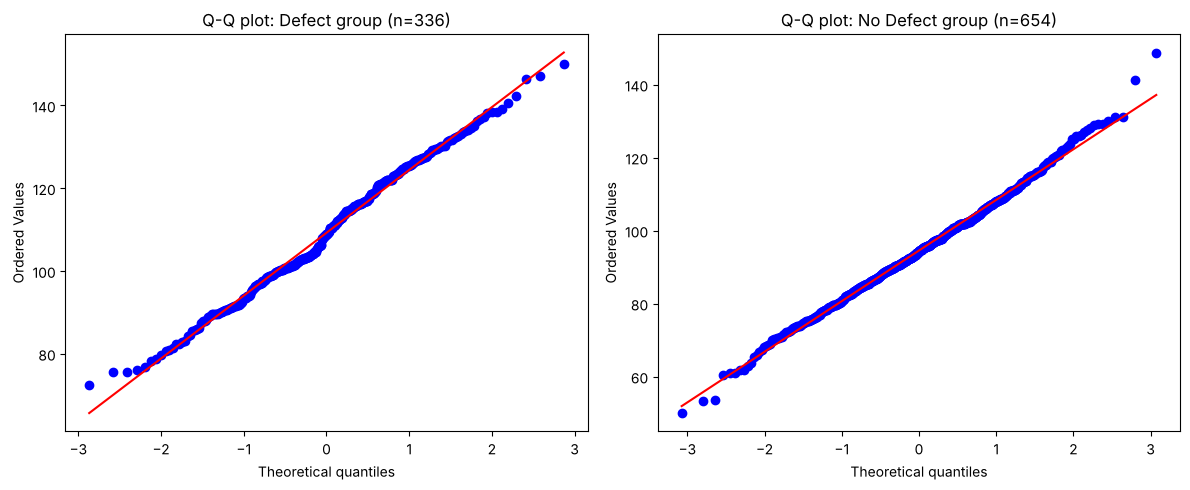

In [14]:
# Significance level: we reject a null hypothesis when p < alpha
alpha = 0.05

# Shapiro-Wilk test on each group. It returns W (test statistic) and p (p-value).
shapiro_defect_w, shapiro_defect_p = stats.shapiro(defect_group)
shapiro_no_defect_w, shapiro_no_defect_p = stats.shapiro(no_defect_group)

print('Shapiro-Wilk test (H0: the data are normally distributed)')
print(f"alpha = {alpha}")
print()

# --- Defect group ---
print(f"Defect group:    W = {shapiro_defect_w:.4f}, p = {shapiro_defect_p:.4f}")
if shapiro_defect_p < alpha:
    defect_is_normal = False
    print('  p < alpha -> reject H0 -> the Defect group is NOT normally distributed.')
else:
    defect_is_normal = True
    print('  p >= alpha -> cannot reject H0 -> the Defect group is treated as normal.')

# --- No Defect group ---
print(f"No Defect group: W = {shapiro_no_defect_w:.4f}, p = {shapiro_no_defect_p:.4f}")
if shapiro_no_defect_p < alpha:
    no_defect_is_normal = False
    print('  p < alpha -> reject H0 -> the No Defect group is NOT normally distributed.')
else:
    no_defect_is_normal = True
    print('  p >= alpha -> cannot reject H0 -> the No Defect group is treated as normal.')

# --- Q-Q plots: one panel per group ---
fig, (ax_qq_defect, ax_qq_no_defect) = plt.subplots(1, 2, figsize=(12, 5))

stats.probplot(defect_group, dist='norm', plot=ax_qq_defect)
ax_qq_defect.set_title(f"Q-Q plot: Defect group (n={len(defect_group)})")

stats.probplot(no_defect_group, dist='norm', plot=ax_qq_no_defect)
ax_qq_no_defect.set_title(f"Q-Q plot: No Defect group (n={len(no_defect_group)})")

plt.tight_layout()
plt.show()

**Step 3.2 – Check that the two groups have equal variances**

Variance measures how spread out the values are. Levene's test checks whether the two groups have the same spread: its null hypothesis is "the variances are equal", so a small p-value (below alpha) means the spreads are different. We use `center='median'`, which makes the test less sensitive to non-normal data.

In [15]:
# Levene's test for equal variances (centre = median version)
levene_statistic, levene_p = stats.levene(defect_group, no_defect_group, center='median')

print("Levene's test (H0: the two groups have equal variances)")
print(f"Test statistic = {levene_statistic:.4f}, p = {levene_p:.4f}")

if levene_p < alpha:
    equal_variances = False
    print('p < alpha -> reject H0 -> the variances are NOT equal.')
else:
    equal_variances = True
    print('p >= alpha -> cannot reject H0 -> the variances are treated as equal.')

Levene's test (H0: the two groups have equal variances)
Test statistic = 10.0556, p = 0.0016
p < alpha -> reject H0 -> the variances are NOT equal.


**Step 3.3 – Select the test using the assumption checks**

The results of Steps 3.1 and 3.2 decide which test is suitable. If both groups are normal and the variances are equal we use the independent t-test; if both are normal but the variances differ we use Welch's t-test; if either group is not normal we use the Mann-Whitney U test, which does not need the normal assumption. The code below follows these rules and prints its choice.

In [16]:
# Results of the assumption checks (True / False from Steps 3.1 and 3.2)
print('Defect group normal?    ', defect_is_normal)
print('No Defect group normal? ', no_defect_is_normal)
print('Equal variances?        ', equal_variances)

# Decision rules
if defect_is_normal and no_defect_is_normal and equal_variances:
    selected_test = 'Independent samples t-test'
elif defect_is_normal and no_defect_is_normal and not equal_variances:
    selected_test = "Welch's t-test"
else:
    selected_test = 'Mann-Whitney U test'

print()
print('Selected test:', selected_test)

Defect group normal?     False
No Defect group normal?  True
Equal variances?         False

Selected test: Mann-Whitney U test


**Step 3.4 – Mann-Whitney U test and effect size**

The Mann-Whitney U test compares the two groups by ranking all the values together and checking whether one group tends to rank higher. Its null hypothesis is that the two groups come from the same distribution. A p-value only says whether there is a difference, so we also calculate the "probability of superiority", which says how large the difference is.

In [17]:
# Mann-Whitney U test (two-sided: we test for a difference in either direction)
mw_result = stats.mannwhitneyu(defect_group, no_defect_group, alternative='two-sided')
mw_u = mw_result.statistic     # SciPy reports U for the FIRST group (defect_group)
mw_p = mw_result.pvalue

print('Mann-Whitney U test (H0: the two groups come from the same distribution)')
print(f"U = {mw_u}")
print(f"p-value = {mw_p:.2e}")
if mw_p < alpha:
    print('p < alpha -> reject H0 -> clamping pressure differs significantly between Defect and No Defect units.')
else:
    print('p >= alpha -> cannot reject H0 -> no significant difference found.')

# Effect size: probability of superiority = U / (n_defect x n_no_defect).
# There are n_defect x n_no_defect possible pairs (one defective unit, one non-defective unit).
# This is the chance that a randomly picked DEFECTIVE unit has a HIGHER clamping pressure
# than a randomly picked NON-DEFECTIVE unit (a tie counts as half).
# 0.5 would mean no difference; 1.0 would mean the defective unit is always higher.
number_of_pairs = len(defect_group) * len(no_defect_group)
probability_of_superiority = mw_u / number_of_pairs

# Rank-biserial correlation: the same effect size rescaled to run from -1 to +1 (0 = no difference)
rank_biserial = 2 * probability_of_superiority - 1

print()
print(f"Probability of superiority = {probability_of_superiority:.3f}")
print(f"Rank-biserial correlation  = {rank_biserial:.3f}")

Mann-Whitney U test (H0: the two groups come from the same distribution)
U = 167195.5
p-value = 2.83e-41
p < alpha -> reject H0 -> clamping pressure differs significantly between Defect and No Defect units.

Probability of superiority = 0.761
Rank-biserial correlation  = 0.522


**Step 3.5 – How big is the difference? (Hodges-Lehmann estimate and 95% confidence interval)**

The Mann-Whitney test tells us there is a difference but not how many bar it is. The Hodges-Lehmann estimate is the middle (median) of all possible differences between a defective unit and a non-defective unit. We also find a 95% confidence interval, a range of believable values for the true difference, using a method that matches the Mann-Whitney test.

In [18]:
# Step A: every possible difference (defective unit - non-defective unit).
# np.subtract.outer subtracts each no-defect value from each defect value.
# ravel() flattens the result into one long list, and sort() puts it in order.
pairwise_diffs = np.subtract.outer(defect_group.values, no_defect_group.values).ravel()
pairwise_diffs = np.sort(pairwise_diffs)

# Step B: the Hodges-Lehmann estimate = the median of all the differences
hl_estimate = np.median(pairwise_diffs)

# Step C: the confidence interval from the sorted differences
n1 = len(defect_group)                       # size of group 1 (Defect)
n2 = len(no_defect_group)                    # size of group 2 (No Defect)
N = n1 * n2                                  # number of differences (pairs)
z = stats.norm.ppf(1 - alpha / 2)            # 1.96 for a 95% interval

# k = how many of the smallest (and largest) differences are cut off at each end
k = int(np.floor(N / 2 - z * np.sqrt(n1 * n2 * (n1 + n2 + 1) / 12)))

# The k-th smallest difference is at position k - 1 (Python counts from 0).
# The k-th largest difference is at position N - k.
ci_lower = pairwise_diffs[k - 1]
ci_upper = pairwise_diffs[N - k]

print(f"Number of pairs (N = n1 x n2) = {n1} x {n2} = {N}")
print(f"z = {z:.2f}, k = {k}")
print()
print(f"Hodges-Lehmann estimate of the shift (Defect - No Defect): {hl_estimate:.2f} bar")
print(f"95% confidence interval: {ci_lower:.2f} to {ci_upper:.2f} bar")

Number of pairs (N = n1 x n2) = 336 x 654 = 219744
z = 1.96, k = 101522

Hodges-Lehmann estimate of the shift (Defect - No Defect): 14.70 bar
95% confidence interval: 12.70 to 16.70 bar


**Step 3.6 – Sensitivity check with Welch's t-test (secondary check only)**

The main test is the Mann-Whitney U test chosen in Step 3.3. As a cross-check we also run Welch's t-test, which compares the means and does not assume equal variances. This is only a sensitivity check: we want to see whether a different, reasonable method gives the same conclusion.

In [19]:
# Welch's t-test: equal_var=False means "do not assume equal variances"
welch_result = stats.ttest_ind(defect_group, no_defect_group, equal_var=False)
welch_t = welch_result.statistic
welch_p = welch_result.pvalue
welch_df = welch_result.df

# 95% confidence interval for the difference in means (Defect - No Defect)
welch_ci = welch_result.confidence_interval(0.95)

print("SENSITIVITY CHECK ONLY - Welch's t-test (not the main test)")
print(f"t = {welch_t:.2f}, degrees of freedom = {welch_df:.1f}")
print(f"p-value = {welch_p:.2e}")
print(f"95% CI for the difference in means (Defect - No Defect): {welch_ci.low:.2f} to {welch_ci.high:.2f} bar")

# Do the two tests lead to the same conclusion?
mw_is_significant = mw_p < alpha
welch_is_significant = welch_p < alpha
print()
if mw_is_significant == welch_is_significant:
    print("Welch's t-test AGREES with the Mann-Whitney U conclusion.")
else:
    print("Welch's t-test DISAGREES with the Mann-Whitney U conclusion.")

SENSITIVITY CHECK ONLY - Welch's t-test (not the main test)
t = 14.87, degrees of freedom = 625.3
p-value = 4.78e-43
95% CI for the difference in means (Defect - No Defect): 12.76 to 16.64 bar

Welch's t-test AGREES with the Mann-Whitney U conclusion.


**Null and alternative hypothesis (H0 and H1):**

- $H_0$: The distribution of clamping pressure is the same for defective and non-defective units, so neither group tends to have higher values than the other.
- $H_1$: The distributions differ, so one group tends to have systematically higher clamping pressure than the other (two-sided).
- Significance level $\alpha$ = 0.05.

**Assumption check results (normality and variance homogeneity):**

- **Normality (Shapiro-Wilk, each group separately):** Defect W = 0.9913, **p = 0.0451** (< 0.05, so normality is rejected). No Defect W = 0.9965, **p = 0.1672** (> 0.05, so there is no evidence against normality). The Q-Q plots agree. The No Defect points follow the reference line closely, apart from a few extreme values. The Defect points bend back towards the centre at both ends: the lowest values sit above the line and the highest sit below it. This is the pattern of a distribution that is flatter than normal (excess kurtosis -0.55), not a skewed one (skewness 0.052).
- **Equal variances (Levene's test, median-centred):** statistic = 10.06, **p = 0.0016** (< 0.05), so the two groups do not have equal variances (SD 15.15 vs 13.85 bar).

**Statistical test used:** I used the **Mann-Whitney U test** (two-sided, two independent samples).

**Why you chose this test:**

- The two groups are **independent**: each unit is either defective or not, and they are different units. The outcome (`Clamping_Pressure`) is continuous.
- A t-test assumes each group is normally distributed. The Shapiro-Wilk test rejected normality for the Defect group (p = 0.0451 < 0.05), so I followed the decision rule and chose the Mann-Whitney U test. It compares the ranks of the values and does not need normality.
- Levene's test (p = 0.0016) also rules out the equal-variance (Student's) t-test. Because the spreads differ, I interpret the Mann-Whitney result as "one group tends to have higher values", not strictly "the medians differ", and I wrote $H_0$ and $H_1$ to match.
- The Defect p-value (0.0451) is only just below 0.05, and with 336 units Shapiro-Wilk can detect small departures. So I ran **Welch's t-test as a sensitivity check** to see whether the conclusion depends on this borderline decision.

**Test result and interpretation:**

- **Result:** U = 167,195.5, **p = $2.83 \times 10^{-41}$**.
- **Meaning of the p-value:** If clamping pressure truly had the same distribution in defective and non-defective units, the probability of getting a difference between the groups at least as large as the one observed, from random sampling alone, would be about $2.83 \times 10^{-41}$, which is effectively zero. It is *not* the probability that $H_0$ is true.
- **Decision:** Since p < 0.05, I **reject $H_0$**. There is very strong statistical evidence that defective units tend to have higher clamping pressure than non-defective units in this dataset. This test shows an association; it does not show that clamping pressure causes the defects.
- **Size of the difference (95% confidence interval for this test):** The Hodges-Lehmann estimate of the shift (Defect minus No Defect) is **14.70 bar**, with a **95% confidence interval of 12.70 to 16.70 bar**. In plain terms, we are 95% confident that the typical difference in clamping pressure between a defective and a non-defective unit on this line is between 12.7 and 16.7 bar higher for defective units. The interval does not include 0, which agrees with rejecting $H_0$. Even the lower limit (12.7 bar, about 13% of the No Defect median of 94.35 bar) is a practically large gap. The interval is narrow (4 bar wide) because the samples are large.
- **Effect size:** The probability of superiority is **0.761**. If one defective and one non-defective unit are picked at random, the defective unit has the higher clamping pressure about 76% of the time, compared with 50% if there were no difference. The rank-biserial correlation of 0.522 indicates a large effect.
- **Sensitivity check:** Welch's t-test gives t = 14.87, p = $4.78 \times 10^{-43}$, and a difference in means of 14.70 bar (95% CI 12.76 to 16.64 bar). This is the same conclusion, so the result does not depend on the borderline normality decision.

## SECTION 4: ENGINEERING IMPLICATIONS

What do your visual and statistical findings jointly imply? What is your proposed course of action? What are the limits of your evidence (e.g. sample size, what your data can and cannot rule out)?

**Your answer:**

**What the findings jointly imply.** The chart shows defective units clustered at higher clamping pressures (median 108.90 vs 94.35 bar), and the defect rate rises steadily from 11.9% below 90 bar to 78.0% at 120 bar and above. The Mann-Whitney U test confirms this is not a chance pattern (p = $2.83 \times 10^{-41}$) and puts the typical shift at 14.70 bar (95% CI 12.70 to 16.70 bar). Together, the visual and statistical evidence show that **high clamping pressure is strongly associated with defects on this line**, making it a strong candidate driver to test. A plausible engineering mechanism exists: excessive clamping force can distort the workpiece while it is machined, and when it is unclamped it springs back out of tolerance. Clamping pressure is also higher on thinner workpieces (r = -0.55 with `Material_Thickness`), which distort more easily. However, this data cannot confirm the mechanism.

**Proposed course of action (scoped to what the evidence supports).** Run a **controlled trial on this CNC line**, not a plant-wide change:

1. Lower the clamping pressure set-point to about **85 to 100 bar**, inside the 85.33 to 102.78 bar range where the middle half of non-defective units were made, for alternating batches or shifts. Keep all other settings unchanged, and run the current setting in the other batches as the comparison group.
2. Before and during the trial, confirm the workpiece is still held securely: no slipping and no rise in `Vibration_Amplitude` or `Alignment_Error`, because too little clamping can cause its own defects.
3. **How the effect will be checked:** after at least about 150 inspected units per setting, compare the defect rate of the reduced-pressure batches with the current-setting batches using a two-proportion (chi-square) test. Plot the defect rate per batch on a control chart. Adopt the lower range only if the defect rate falls clearly and surface roughness and alignment do not get worse.

**Limits of the evidence.**

1. **Association, not cause (other parameters move with pressure).** Clamping pressure is strongly correlated with `Tool_Wear` (r = -0.76), `Machine_Load` (r = 0.63) and `Material_Thickness` (r = -0.55), and all three also differ between the groups (Defect vs No Defect medians: tool wear 0.4 vs 0.6 mm, load 60.3 vs 56.6%, thickness 4.5 vs 5.1 mm). A comparison of one parameter cannot separate these, so the defects could be driven by, for example, thinner material, with pressure simply moving along with it. This is why I propose a controlled trial rather than an immediate change.
2. **Pressure cannot sort individual parts.** The groups overlap heavily: defective units range from 72.5 to 150.0 bar, non-defective units reach 148.8 bar, and 11.9% of units below 90 bar were still defective. Lowering pressure is therefore unlikely to remove all defects, and pressure cannot be used as a pass/fail check for single parts.
3. **What the data does not record.** The `defect` column is only yes/no, so we do not know which kind of defect (dimensional, surface or crack) is linked to pressure. We also do not know how the pressure was chosen (operator, part type or recipe) or which period and part types the 990 units cover. In addition, there are no readings below 50 bar, so the data cannot say how low pressure can safely go.
4. **Data-logging quality.** 10 blank rows and a `Lubricant_Flow_Rate` column that exactly copies `Humidity` suggest logging problems. The pressure readings themselves looked plausible, but the logging system should be checked before the trial.


## SECTION 5A: STAKEHOLDER SUMMARY — VISUAL FINDINGS

Write a short, jargon-free summary of your visual findings and their implication, for the plant manager (non-technical, no statistics background).

**Your answer:**

We looked at how tightly the machine clamped each part (the clamping pressure, measured in bar) for 990 recent parts: 336 that failed inspection and 654 that passed.

**What we saw:** Parts that failed inspection had usually been clamped harder. A typical failed part was clamped at about 109 bar, compared with about 94 bar for a typical good part, which is roughly 15 bar (about 15%) more. The pattern is steady. When parts were clamped below 90 bar, about 1 in 8 failed. Between 110 and 120 bar, more than half failed. At 120 bar and above, nearly 4 in 5 failed.

**What this means:** Clamping pressure is a strong warning sign for defects on this line, and it is a setting we control, so it is a sensible first place to act. However, good and failed parts overlap a lot: some parts clamped hard were fine, and some clamped lightly still failed. Pressure is therefore not the whole story.

**What we recommend:** Run a short, controlled trial on this line. Lower the clamping pressure to about 85 to 100 bar (the range where most good parts were made) on some batches, keep everything else the same, and compare their failure rate with batches at the normal setting. At the same time, make sure parts are still held firmly and do not slip.

**What we cannot tell yet:** The data shows that higher pressure and failures go together, not that the pressure causes the failures. Parts that were clamped harder also tended to have thinner material, less tool wear and a heavier machine load, and any of these could be the real cause. The trial is how we will find out.


## SECTION 5B: STAKEHOLDER SUMMARY — STATISTICAL FINDINGS

Write a short, jargon-free summary of your statistical findings and their implication, for the same reader.

**Your answer:**

We used a standard statistical check to answer one question: *could the difference in clamping pressure between failed and good parts just be a coincidence in which parts happened to be recorded?*

**The finding:** No. The difference is far too large and too consistent to be chance. If clamping pressure had nothing to do with failures, the chance of seeing a gap this big would be practically zero (much smaller than one in a billion). We also repeated the check with a second method, and it gave the same answer.

**How big the difference is:** Our best estimate is that failed parts were clamped about **15 bar harder** than good parts. Because we only have a sample of 990 parts, there is some uncertainty, but the true gap is very likely between **13 and 17 bar**. Put another way, if you pick one failed part and one good part at random, the failed part was clamped harder about **3 times out of 4**.

**How much to trust it:** We can be highly confident that this difference is real for this line and this set of parts.

**What we recommend:** Trial a lower clamping pressure (about 85 to 100 bar) on some batches while keeping other settings the same. Then compare their failure rate with normal batches, using the same kind of check to confirm whether any drop is real. Make the lower setting standard only if failures fall clearly and parts are still held securely.

**What this cannot tell us yet:** It shows that higher pressure and failures go together, not that pressure causes failures, because several other machine settings changed together with pressure. It also does not tell us which type of defect is involved, or how low the pressure can safely go, since we have no data below 50 bar and too little clamping can let the part move.


## SECTION 6: PROCESS REFLECTION

These answers should be honest, specific, and refer to your own actual results and decisions. **300-word limit for your combined response.** You may be asked about this material in the viva.

**1. Describe a real problem you encountered.** Explain what you expected to happen and what happened instead. Be specific and avoid vague statements such as simply saying you were confused.

**2. Explain your first response.** Describe the first thing you did to try to resolve the issue and why you chose to do that. This could include things like checking your data, revisiting your analysis choice, or examining the output more closely.

**3. Describe what you learnt and how you applied it.** Explain one clear thing you learnt about data analysis, how you learnt it, and how that learning helped you change or improve your analysis.

**4. End with a clear insight.** End your reflection with a short insight about how this experience improved your understanding of data analysis. This insight should be connected to what actually happened in this task.

**Your answer:**

**[DRAFT - Lokman: rewrite this in your own words, based on what you actually experienced when running the notebook. Delete this line before submitting.]**

**Problem:** I expected `Clamping_Pressure` to pass the normality check in both groups, because the histogram looked bell-shaped and the Defect group's skewness was only 0.052. Instead, Shapiro-Wilk gave p = 0.0451 for the Defect group, just below 0.05, while the No Defect group passed (p = 0.1672). My planned t-test was no longer justified, and I was unsure whether such a borderline result should really change the test.

**First response:** Instead of looking for a way to make the data "pass", I examined the output more closely. I checked the Q-Q plot and the kurtosis (-0.55), which showed the Defect group is slightly flatter than a normal curve rather than skewed. I then ran Levene's test, which gave p = 0.0016, so the spreads also differed.

**What I learnt and applied:** I learnt that with large samples (336 units), Shapiro-Wilk can flag quite small departures from normality, so its p-value tells me a departure is detectable, not that it is large. I learnt this by comparing the test result with the shape statistics and plots. I applied it by following the decision rule: I chose the Mann-Whitney U test, which does not need normality, with its matching Hodges-Lehmann interval (12.70 to 16.70 bar). I then ran Welch's t-test as a sensitivity check. Both gave the same conclusion, a shift of about 14.7 bar with p far below 0.05, so I could report the result with confidence instead of worrying about a borderline p-value.

**Insight:** An assumption check is not a gate to get through. It is evidence about the shape of the data. Checking whether my conclusion survived a different reasonable test made me more confident in it than any single p-value could.

## APPENDIX A: AI USAGE LOG

Submit your complete, unedited AI chat log as a **separate file** alongside this notebook (not pasted into a cell here). Name it `AI_Usage_Log` with an appropriate extension (e.g. `.txt`, `.pdf`, or exported chat history). Do not summarise or clean it up — submit the full conversation history for any AI tool you used on this project.

**Confirm here that you have attached this file separately:** *(yes / no)*
